# MEN 03 — Normalizing motion energy

ME is never negative and the mouse is still much of the time, so the session mean sits above the
still level and z-scoring puts stillness below zero. This notebook puts the bottom-camera ME of the
88 FIP sessions (20 Hz grid, as in the `fip_*` notebooks) on three scales, all from
`fu.normalise_me`, and reruns every FIP analysis that reads ME amplitude on each.

| Scale | `me_norm` | Formula (per session) | 0 is |
|---|---|---|---|
| z-score | `zscore` | (ME − mean) / SD | the session mean |
| ÷ SD | `sd` | ME / SD | no pixel change |
| floor ÷ SD | `floor_sd` | max(0, ME − p1) / SD | the session's 1st percentile |

All three divide by the same SD, so within a session they differ only by an offset (and the
clipping of the lowest 1% for `floor_sd`).

**Floor.** Stillness is measured without ME onsets or licks: the 20 Hz trace is cut into 60 s
windows, the 5th percentile of each window (its quietest 3 s) is taken, and the session's floor is
the median over windows. ME onsets (`fu.ME_ONSET_KW`, on the z-scored 100 Hz trace) are the same
on every scale.

1. Example traces
2. Where the floor sits on each scale, and what sets the SD
3. Fast fluctuation (flickering reflections) against the floor and the SD
4. Analyses that change with the scale (`fip_12` §1–2, `fip_11` §4, `fip_16` §6)
5. Analyses that do not (`fip_10` correlations, `fip_13` R², `fip_16` DA/NE terms with ME as a covariate)
6. Numbers

**Decision (2026-10-22).** ME traces, levels, responses, regressions and figures use floor ÷ SD (the default of
`fu.add_motion_energy` and `men_*`'s `ME_NORM`); ME onsets stay on the z-scored trace; DA and NE stay
z-scored. Within a session the scales differ only by a constant, so only ME *levels* read differently, and
for levels the floor is the zero that means the same in every session.

## Setup

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from scipy import signal, stats

import fip_utils as fu
import signal_utils as su
import stats_utils as st
import behavior_utils as bu
import plot_utils as pu
from plotstyle import apply_style, style_ax, save_fig, PALETTE, OKABE_ITO

apply_style()
warnings.filterwarnings("ignore", message="Mean of empty slice")
warnings.filterwarnings("ignore", message="Sample size too small for normal approximation")
warnings.filterwarnings("ignore", message="Exact p-value calculation does not work if there are zeros")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

In [2]:
IS_CO = os.path.isdir("/root/capsule")

ASSET_CANDIDATES = {
    "3ch": ["/root/capsule/data/DANE_3channels_curated",
            "../../data/results-a278f830-9bf2-48e8-9928-a2ff78e4818f"],
    "4ch": ["/root/capsule/data/DANE_4channels_curated",
            "../../data/results-ddcccb0f-f18f-44a6-a2b1-caba680d28a1"],
}
ME_DATA_ROOT = "/root/capsule/data" if IS_CO else os.environ.get("ME_DATA_ROOT", "../../data")
PAIRS_CACHE = ("/root/capsule/scratch/fip_05/pairs.pkl" if IS_CO
               else "../../data/fip_05_cache/pairs.pkl")
FIG_DIR = "/root/capsule/scratch/figures/men" if IS_CO else "../data/figures/men"
SAVE_FIG = True

# ── Data (as fip_12) ─────────────────────────────────────────────────────────
FS = 20.0                  # Hz, the common grid
CAMERA = "BottomCamera"
MIN_SESSIONS_PER_ANIMAL = 3
EXCLUDE_SUBJECTS = ()
FS_ONSET = 100.0           # Hz, ME onsets are detected at men_00's rate

# ── Floor and fast fluctuation ───────────────────────────────────────────────
FLOOR_WIN_S = 60.0         # window for the floor
FLOOR_WIN_PCT = 5          # percentile of each window taken as its floor
FAST_HZ = 10.0             # "fast": above the 20 Hz grid's Nyquist frequency
FAST_SHARE_CUT = 0.35      # sessions above this share of ME power > FAST_HZ are listed (descriptive)
FS_CAMERA = 500.0

# ── Analyses (each as in its notebook) ───────────────────────────────────────
ETA_LAGS = np.arange(-2.0, 3.0 + 1e-9, 1 / FS)
INSTRUCTED_S = 2.0                          # fip_12 §2
LICK_WIN = (-0.5, 1.0)
PRE_WIN = (-1.0, -0.2)
RESP_WIN = (0.0, 1.0)
LARGE_PROM, PARTNER_PROM, MATCH_WIN_S, MIN_SEP_S = 2.0, 1.0, 0.5, 0.5   # fip_11 §4
PEAK_WIN = (-0.5, 0.5)
BASELINE_WIN = (-1.0, 0.0)                  # fip_16 §6
OUTCOME_WIN = (0.0, 2.0)
MIN_RPE_SD = 0.05
RPE_NUISANCE = ["response_time", "trial_frac"]
TERMS = ["reward", "rpe_rew", "rpe_unrew"]
KERNEL_S = (-1.0, 4.0)                      # fip_13
ME_LAGS_S = (-1.0, 2.0)
N_R2_SESSIONS = 12                          # sessions in the R² check (section 5)

# ── Scales ───────────────────────────────────────────────────────────────────
SCALES = ["z-score", "÷ SD", "floor ÷ SD"]
NORM_OF = dict(zip(SCALES, ["zscore", "sd", "floor_sd"]))
SCALE_COLOR = dict(zip(SCALES, ["0.2", OKABE_ITO["sky_blue"], OKABE_ITO["blue"]]))
SCALE_UNIT = dict(zip(SCALES, ["z", "SD", "SD above p1"]))
TYPE_COLOR = {"instructed, rewarded": OKABE_ITO["orange"], "instructed, unrewarded": "0.55",
              "uninstructed lick bout": OKABE_ITO["bluish_green"],
              "movement, no lick": OKABE_ITO["reddish_purple"]}
TYPES = list(TYPE_COLOR)
FAST_COLOR = OKABE_ITO["vermillion"]

## 0. Data

Pairs, ME onsets and raw ME on the 20 Hz grid from `fu.add_motion_energy(..., keep_raw=True)`. Each
scale is `fu.normalise_me` of the raw trace, with empty bins set to the session mean on that scale
(0 for the z-score), as `add_motion_energy` does.

In [3]:
asset_roots = {}
for name, cands in ASSET_CANDIDATES.items():
    root = fu.find_asset_root(cands)
    if root:
        asset_roots[name] = root
assert asset_roots, "no FIP asset found; check ASSET_CANDIDATES"

inv = fu.inventory_pairs(asset_roots)
kept, side_table = fu.choose_side(inv, MIN_SESSIONS_PER_ANIMAL)
all_pairs = fu.load_pairs(kept, fs=FS, cache_path=PAIRS_CACHE)
pairs = fu.add_motion_energy(all_pairs, kept, CAMERA, ME_DATA_ROOT, onset_fs=FS_ONSET,
                             exclude_subjects=EXCLUDE_SUBJECTS, keep_raw=True)


def on_scale(raw, how):
    # fu.normalise_me with empty bins at the session mean on that scale, as add_motion_energy
    x = fu.normalise_me(raw, how)
    return np.where(np.isfinite(x), x, 0.0 if how == "zscore" else np.nanmean(x))


for p in pairs:
    p["me"] = {sc: on_scale(p["me_raw"], NORM_OF[sc]) for sc in SCALES}
assert all(np.allclose(p["me"]["floor ÷ SD"], p["z"]["me"]) for p in pairs)

SUBJECTS = sorted({p["subject"] for p in pairs})
N_ANIMALS = len(SUBJECTS)
print(f"{len(pairs)} sessions, {N_ANIMALS} animals; floor ÷ SD matches add_motion_energy's ME (its default)")

loaded 97 pairs from cache ../../data/fip_05_cache/pairs.pkl


88 sessions, 9 animals; floor ÷ SD matches add_motion_energy's ME (its default)


In [4]:
def window_floors(x):
    # floor of each FLOOR_WIN_S window: its FLOOR_WIN_PCT-th percentile
    n = int(FLOOR_WIN_S * FS)
    return np.array([np.percentile(x[i * n:(i + 1) * n], FLOOR_WIN_PCT) for i in range(len(x) // n)])


def animal_traces(per_session):
    # [(subject, trace)] -> (n_animals, n_lags): session traces averaged within animal
    if not per_session:
        return np.empty((0, len(ETA_LAGS)))
    subj, traces = zip(*per_session)
    return st.group_means(traces, subj)[1]


rows = []
for p in pairs:
    raw = p["me_raw"][np.isfinite(p["me_raw"])]
    sd = np.std(raw, ddof=1)
    w = window_floors(raw)
    r = dict(subject=p["subject"], session=p["session"], sd=sd, floor_raw=np.median(w),
             floor_sd_units=np.median(w) / sd, floor_range_sd=(np.percentile(w, 90) - np.percentile(w, 10)) / sd,
             onsets_per_min=len(p["me_onsets"]) / (len(p["me_raw"]) / FS / 60))
    for sc in SCALES:
        r[f"floor: {sc}"] = np.median(window_floors(p["me"][sc]))
    p["floor_windows"] = w
    rows.append(r)
floor_sess = pd.DataFrame(rows)

## 1. Example traces

The sessions with the lowest, median and highest floor in SD units (raw floor ÷ session SD). One
minute from the middle of each. Dashed: the session's floor on that scale; dotted: 0; ticks: ME onsets.

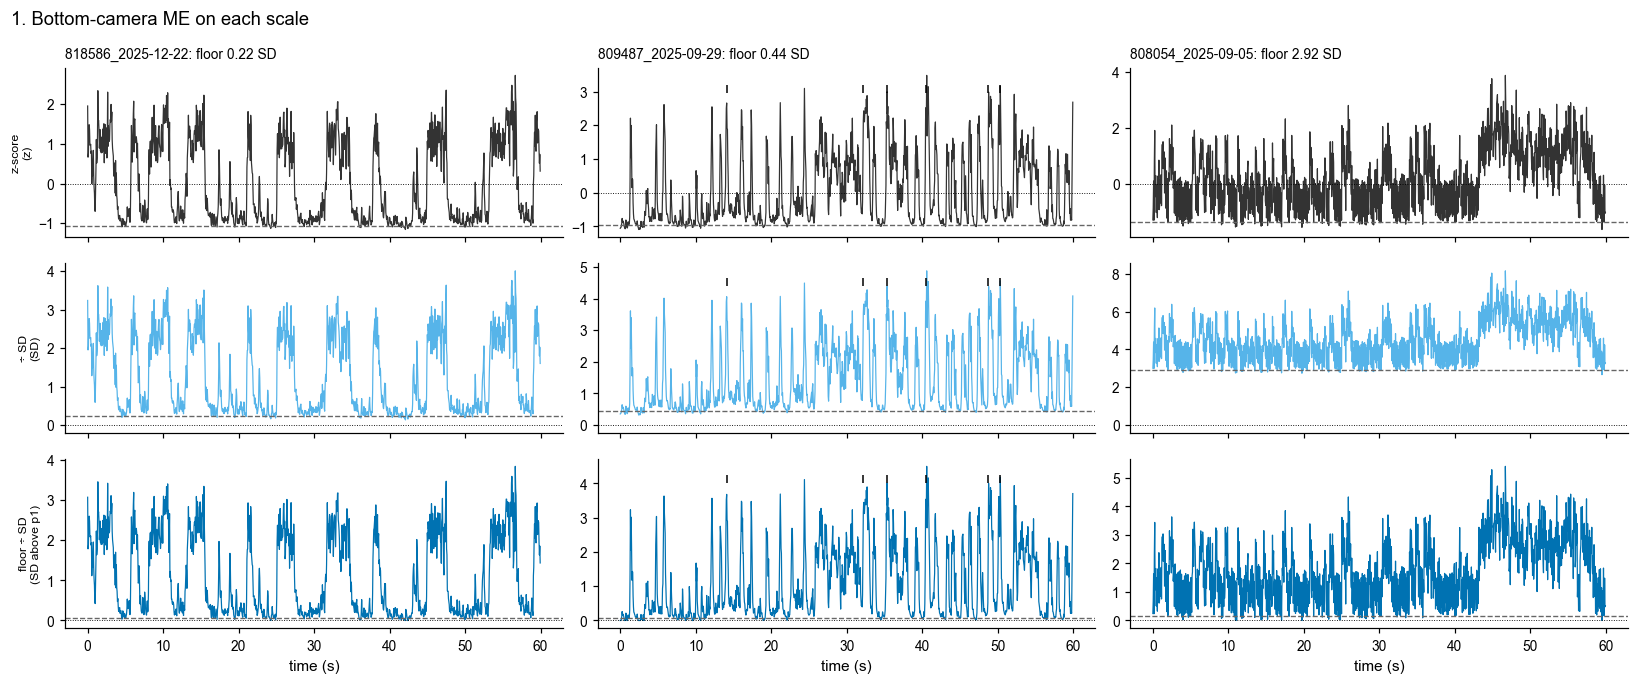

In [5]:
srt = floor_sess.reset_index().sort_values("floor_sd_units")
examples = [srt.iloc[0], srt.iloc[len(srt) // 2], srt.iloc[-1]]
WIN_S = 60.0

fig, axes = plt.subplots(len(SCALES), 3, figsize=(15, 2.1 * len(SCALES)), sharex="col")
for c, row in enumerate(examples):
    p = pairs[int(row["index"])]
    n = len(p["me_raw"])
    i0 = n // 2
    i1 = i0 + int(WIN_S * FS)
    t = np.arange(i1 - i0) / FS
    for r, sc in enumerate(SCALES):
        ax = axes[r, c]
        x = p["me"][sc]
        ax.plot(t, x[i0:i1], color=SCALE_COLOR[sc], lw=0.8)
        ax.axhline(row[f"floor: {sc}"], color="0.4", lw=0.9, ls="--")
        ax.axhline(0, color="k", lw=0.6, ls=":")
        on = p["me_onsets"]
        on = on[(on >= p["t0"] + i0 / FS) & (on < p["t0"] + i1 / FS)] - (p["t0"] + i0 / FS)
        ax.plot(on, np.full(len(on), np.percentile(x[i0:i1], 99.5) * 1.05), "|", color="k", ms=5)
        if c == 0:
            ax.set_ylabel(f"{sc}\n({SCALE_UNIT[sc]})", fontsize=8)
        if r == 0:
            ax.set_title(f"{p['session']}: floor {row['floor_sd_units']:.2f} SD", loc="left", fontsize=9)
        style_ax(ax)
    axes[-1, c].set_xlabel("time (s)")
fig.suptitle("1. Bottom-camera ME on each scale", x=0.01, ha="left")
fig.tight_layout()
save_fig(fig, "men_03_1_example_traces", fig_dir=FIG_DIR, save=SAVE_FIG)
plt.show()

## 2. Where the floor sits, and what sets the SD

**a.** The floor of every session on each scale. **b.** The floor across the session: its spread
over the 60 s windows (90th − 10th percentile), in session SDs. **c.** The SD (raw ME) against how
much the mouse moves (ME onsets per minute): a divisor that grew with movement would shrink the ME
of sessions with more movement.

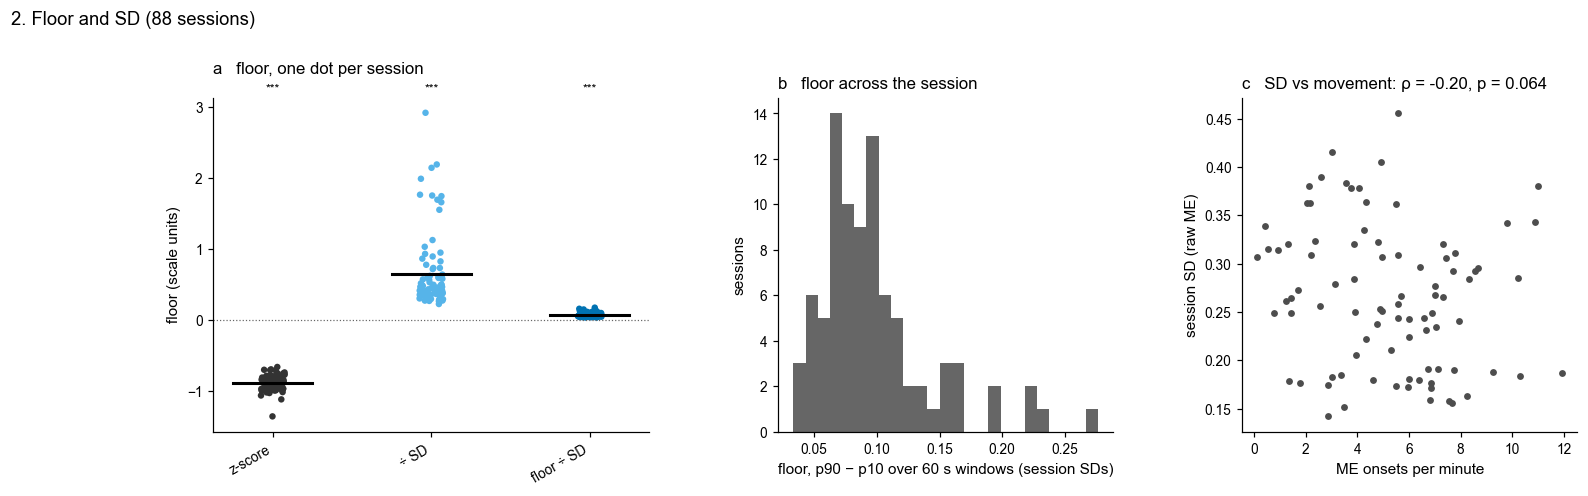

                    mean    50%    min    max
floor: z-score    -0.895 -0.886 -1.360 -0.664
floor: ÷ SD        0.640  0.440  0.223  2.919
floor: floor ÷ SD  0.072  0.064  0.034  0.172
floor_sd_units     0.640  0.440  0.223  2.919
floor_range_sd     0.098  0.089  0.033  0.276


In [6]:
fig = plt.figure(figsize=(16, 4.4))
gs = GridSpec(1, 3, figure=fig, width_ratios=[1.3, 1, 1], wspace=0.35, top=0.8)
ax = fig.add_subplot(gs[0])
pu.strip_by_measure(ax, floor_sess, [f"floor: {sc}" for sc in SCALES], SCALES,
                    [SCALE_COLOR[sc] for sc in SCALES], "floor (scale units)",
                    title="a   floor, one dot per session", connect=False, rng=np.random.default_rng(0))
ax = fig.add_subplot(gs[1])
ax.hist(floor_sess["floor_range_sd"], bins=25, color="0.4")
ax.set_xlabel("floor, p90 − p10 over 60 s windows (session SDs)")
ax.set_ylabel("sessions")
ax.set_title("b   floor across the session", loc="left")
style_ax(ax)
ax = fig.add_subplot(gs[2])
ax.scatter(floor_sess["onsets_per_min"], floor_sess["sd"], s=12, color="0.3")
rho, pv = stats.spearmanr(floor_sess["onsets_per_min"], floor_sess["sd"])
ax.set_xlabel("ME onsets per minute")
ax.set_ylabel("session SD (raw ME)")
ax.set_title(f"c   SD vs movement: ρ = {rho:.2f}, p = {pv:.2g}", loc="left")
style_ax(ax)
fig.suptitle(f"2. Floor and SD ({len(pairs)} sessions)", x=0.01, ha="left")
save_fig(fig, "men_03_2_floor_sd", fig_dir=FIG_DIR, save=SAVE_FIG)
plt.show()

print(floor_sess[[f"floor: {sc}" for sc in SCALES] + ["floor_sd_units", "floor_range_sd"]]
      .describe().T[["mean", "50%", "min", "max"]].round(3).to_string())

## 3. Fast fluctuation against the floor and the SD

In some sessions a flickering reflection on the spouts raises ME while the mouse is still (clips and
spectra in `men_01` §6). It sits above the 20 Hz grid's 10 Hz Nyquist frequency, so averaging into
bins turns it into an offset. Per session, from the 500 Hz trace over the task: the share of ME power
above 10 Hz; and the SD on the 20 Hz grid after a 10 Hz low-pass (4th-order zero-phase Butterworth,
before binning) over the SD as is. **a.** The share across sessions. **b.** SD ratio. **c.** The floor
on the floor ÷ SD scale. Vermillion: sessions above a share of 0.35.

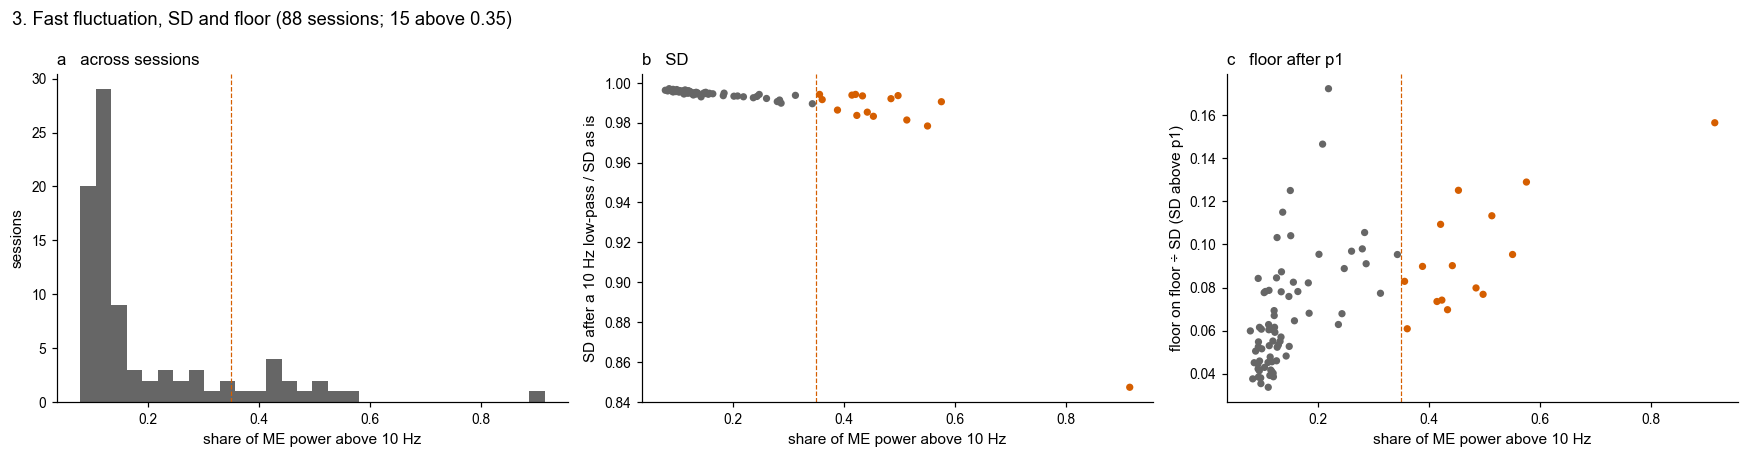

above cut                 False  True 
fast_share        median  0.120  0.442
                  min     0.079  0.356
                  max     0.344  0.915
sd_ratio          median  0.995  0.991
                  min     0.990  0.847
                  max     0.997  0.994
floor: floor ÷ SD median  0.061  0.090
                  min     0.034  0.061
                  max     0.172  0.157
floor_sd_units    median  0.411  1.658
                  min     0.223  0.863
                  max     1.764  2.919
floor_range_sd    median  0.087  0.100
                  min     0.033  0.065
                  max     0.276  0.222

          session  fast_share  sd_ratio  floor: floor ÷ SD  floor_sd_units  floor_range_sd
808054_2025-09-05       0.915     0.847              0.157           2.919           0.222
818586_2026-01-15       0.576     0.991              0.129           2.191           0.107
808054_2025-09-17       0.551     0.978              0.095           1.125           0.087
808054_2025

In [7]:
b_lp, a_lp = signal.butter(4, FAST_HZ / (FS_CAMERA / 2))
path_of = dict(zip(kept["session"], kept["path"]))
fast_rows = []
for p in pairs:
    trials_raw = pd.read_parquet(os.path.join(path_of[p["session"]], "df_trials.parquet"))
    t_me, y, _ = fu.motion_energy_to_session(p["session"], trials_raw, camera=CAMERA, data_root=ME_DATA_ROOT)
    ok = np.isfinite(y)
    yf = np.interp(t_me, t_me[ok], y[ok])               # NaN frames filled for filtering only
    f, P = signal.welch(yf - yf.mean(), fs=FS_CAMERA, nperseg=8192)
    n = len(p["me_raw"])
    lp = su.bin_to_grid(t_me, np.where(ok, signal.filtfilt(b_lp, a_lp, yf), np.nan), p["t0"], FS, n)
    m = np.isfinite(lp) & np.isfinite(p["me_raw"])
    fast_rows.append(dict(session=p["session"], fast_share=P[f > FAST_HZ].sum() / P[f > 0].sum(),
                          sd_ratio=np.std(lp[m], ddof=1) / np.std(p["me_raw"][m], ddof=1)))
floor_sess = floor_sess.drop(columns=["fast_share", "sd_ratio"], errors="ignore").merge(pd.DataFrame(fast_rows), on="session")
fast = floor_sess["fast_share"] > FAST_SHARE_CUT
c = np.where(fast, FAST_COLOR, "0.4")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
ax = axes[0]
ax.hist(floor_sess["fast_share"], bins=30, color="0.4")
ax.axvline(FAST_SHARE_CUT, color=FAST_COLOR, ls="--", lw=0.8)
ax.set_xlabel(f"share of ME power above {FAST_HZ:.0f} Hz")
ax.set_ylabel("sessions")
ax.set_title("a   across sessions", loc="left")
style_ax(ax)
for ax, col, lab, title in ((axes[1], "sd_ratio", f"SD after a {FAST_HZ:.0f} Hz low-pass / SD as is", "b   SD"),
                            (axes[2], "floor: floor ÷ SD", "floor on floor ÷ SD (SD above p1)", "c   floor after p1")):
    ax.scatter(floor_sess["fast_share"], floor_sess[col], s=14, c=c)
    ax.axvline(FAST_SHARE_CUT, color=FAST_COLOR, ls="--", lw=0.8)
    ax.set_xlabel(f"share of ME power above {FAST_HZ:.0f} Hz")
    ax.set_ylabel(lab)
    ax.set_title(title, loc="left")
    style_ax(ax)
fig.suptitle(f"3. Fast fluctuation, SD and floor ({len(pairs)} sessions; {int(fast.sum())} above {FAST_SHARE_CUT})",
             x=0.01, ha="left")
fig.tight_layout()
save_fig(fig, "men_03_3_fast_fluctuation", fig_dir=FIG_DIR, save=SAVE_FIG)
plt.show()

cols = ["fast_share", "sd_ratio", "floor: floor ÷ SD", "floor_sd_units", "floor_range_sd"]
print(floor_sess.groupby(fast.rename("above cut"))[cols].agg(["median", "min", "max"]).round(3).T.to_string())
print()
print(floor_sess.loc[fast, ["session"] + cols].sort_values("fast_share", ascending=False).round(3).to_string(index=False))

## 4. Analyses that change with the scale

Each analysis is the one in its notebook with only the ME trace swapped. The tables give, for each
measure and scale, the mean over animals, the Wilcoxon p across animals and the number of animals
above zero.

### 4a. ME at ME onsets (`fip_12` §1a)

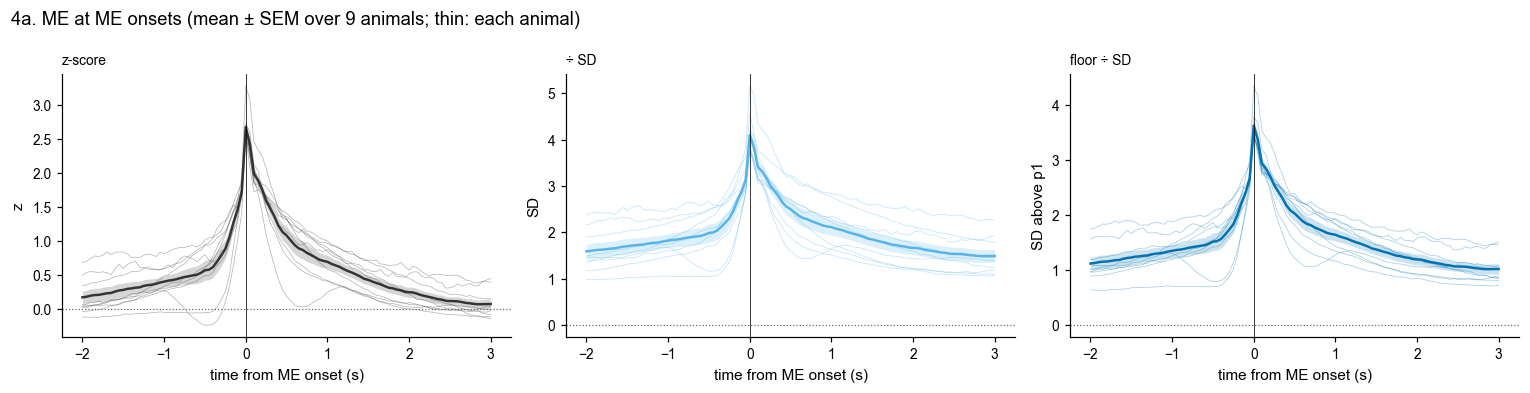

z-score                baseline −2…−1 s +0.27 (animals -0.09…+0.78); peak 2.67 (animals 2.50…3.28, max/min 1.3×)
÷ SD                   baseline −2…−1 s +1.69 (animals +1.02…+2.46); peak 4.10 (animals 3.73…5.16, max/min 1.4×)
floor ÷ SD             baseline −2…−1 s +1.22 (animals +0.67…+1.85); peak 3.63 (animals 3.39…4.35, max/min 1.3×)


In [8]:
eta_onset = {sc: [] for sc in SCALES}
for p in pairs:
    for sc in SCALES:
        eta_onset[sc].append((p["subject"], np.nanmean(su.peri_event_grid(p["me"][sc], p["t0"], FS, p["me_onsets"], ETA_LAGS), 0)))

fig, axes = plt.subplots(1, len(SCALES), figsize=(14, 3.6))
for ax, sc in zip(axes, SCALES):
    pu.plot_mean_sem(ax, ETA_LAGS, animal_traces(eta_onset[sc]), SCALE_COLOR[sc], show_rows=True)
    ax.axvline(0, color="k", lw=0.5)
    ax.axhline(0, color=PALETTE["neutral"], lw=0.8, ls=":")
    ax.set_xlabel("time from ME onset (s)")
    ax.set_ylabel(SCALE_UNIT[sc])
    ax.set_title(sc, loc="left", fontsize=9)
    style_ax(ax)
fig.suptitle(f"4a. ME at ME onsets (mean ± SEM over {N_ANIMALS} animals; thin: each animal)", x=0.01, ha="left")
fig.tight_layout()
save_fig(fig, "men_03_4a_me_onsets", fig_dir=FIG_DIR, save=SAVE_FIG)
plt.show()

for sc in SCALES:
    a = animal_traces(eta_onset[sc])
    base = a[:, (ETA_LAGS >= -2) & (ETA_LAGS < -1)].mean(1)
    pk = a.max(1)
    print(f"{sc:22s} baseline −2…−1 s {base.mean():+.2f} (animals {base.min():+.2f}…{base.max():+.2f}); "
          f"peak {pk.mean():.2f} (animals {pk.min():.2f}…{pk.max():.2f}, max/min {pk.max() / pk.min():.1f}×)")

### 4b. ME by movement type (`fip_12` §2): response 0–1 s minus −1 to −0.2 s

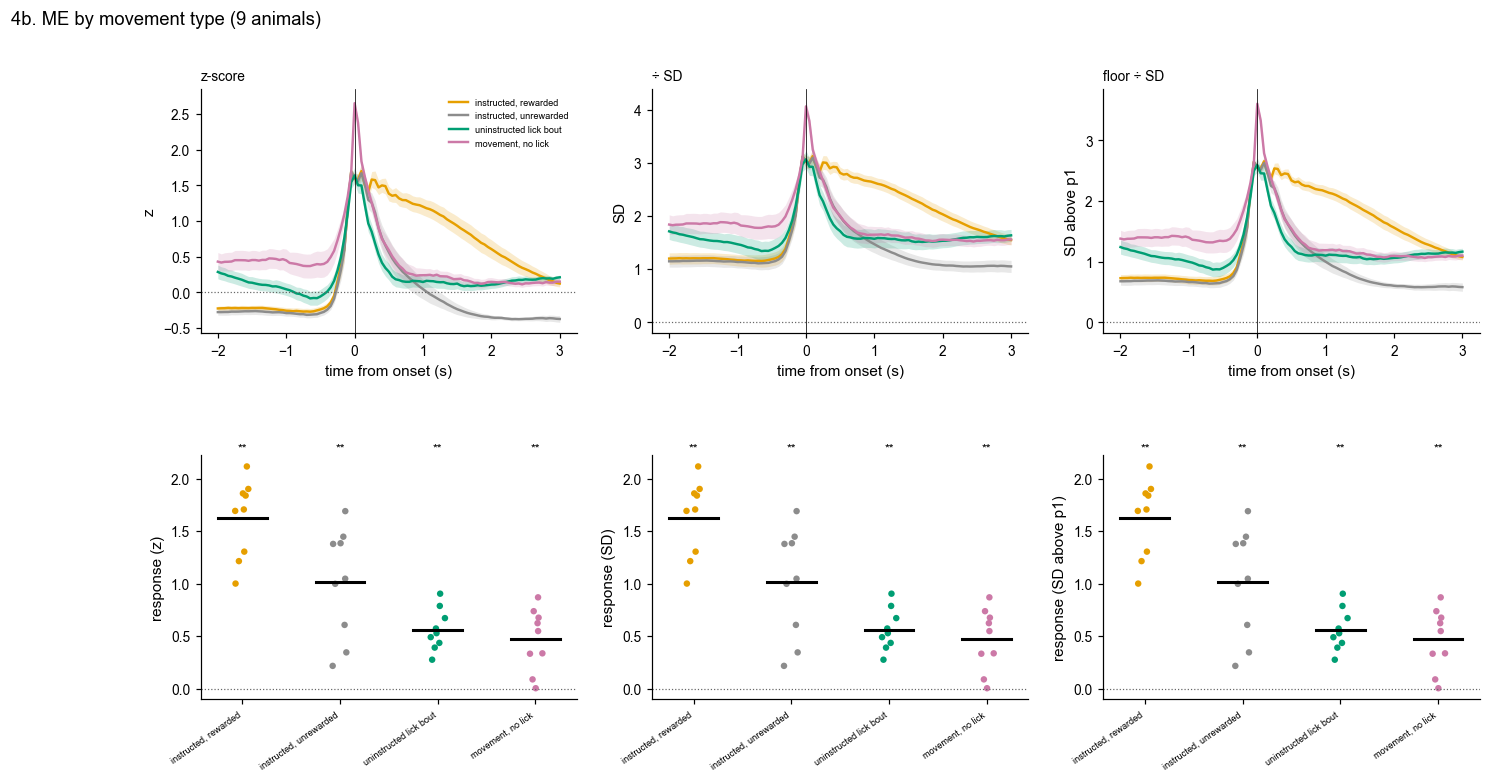

In [9]:
type_rows = []
eta_type = {(sc, k): [] for sc in SCALES for k in TYPES}
for p in pairs:
    tr = p["trials"]
    cues = tr["goCue_start_time_in_session"].to_numpy()
    rewarded = (tr["earned_reward"].fillna(0).astype(bool) & (tr["animal_response"] < 2)).to_numpy()
    span = (np.nanmin(cues), np.nanmax(cues) + 10.0)
    le = p["lick_events"]
    bouts = bu.lick_bouts(le[(le.timestamps >= span[0]) & (le.timestamps < span[1])])
    instr, uninstr = bu.classify_bout_times(bouts["onset"], cues[np.isfinite(cues)],
                                            go_response_window_s=INSTRUCTED_S,
                                            iti_min_post_cue_s=INSTRUCTED_S, iti_min_pre_next_s=0.0)
    order = np.argsort(cues)
    k = order[np.searchsorted(cues[order], instr, side="right") - 1]
    ev = p["me_onsets"]
    ev = ev[(ev >= span[0]) & (ev < span[1])]
    ev = ev[~su.near_any(ev, p["licks"], *LICK_WIN)]
    ev = ev[bu.label_context(ev, tr, p["licks"]) == "quiet"]
    onsets = {"instructed, rewarded": instr[rewarded[k]], "instructed, unrewarded": instr[~rewarded[k]],
              "uninstructed lick bout": uninstr, "movement, no lick": ev}
    r = dict(subject=p["subject"], session=p["session"])
    for typ, t in onsets.items():
        if len(t) < 3:
            continue
        for sc in SCALES:
            x = p["me"][sc]
            eta_type[(sc, typ)].append((p["subject"], np.nanmean(su.peri_event_grid(x, p["t0"], FS, t, ETA_LAGS), 0)))
            r[f"{sc}|{typ}"] = np.nanmean(su.window_mean_grid(x, p["t0"], FS, t, *RESP_WIN)
                                          - su.window_mean_grid(x, p["t0"], FS, t, *PRE_WIN))
    type_rows.append(r)
type_animal = st.animal_means(pd.DataFrame(type_rows), [f"{sc}|{t}" for sc in SCALES for t in TYPES],
                              by_session=False)
for sc in SCALES:   # differences fip_12 reports
    type_animal[f"{sc}|uninstructed − instructed unrewarded"] = (
        type_animal[f"{sc}|uninstructed lick bout"] - type_animal[f"{sc}|instructed, unrewarded"])
    type_animal[f"{sc}|instructed rewarded − unrewarded"] = (
        type_animal[f"{sc}|instructed, rewarded"] - type_animal[f"{sc}|instructed, unrewarded"])

fig, axes = plt.subplots(2, len(SCALES), figsize=(15, 7.2), gridspec_kw=dict(hspace=0.5))
for j, sc in enumerate(SCALES):
    ax = axes[0, j]
    for typ in TYPES:
        pu.plot_mean_sem(ax, ETA_LAGS, animal_traces(eta_type[(sc, typ)]), TYPE_COLOR[typ], typ)
    ax.axvline(0, color="k", lw=0.5)
    ax.axhline(0, color=PALETTE["neutral"], lw=0.8, ls=":")
    ax.set_xlabel("time from onset (s)")
    ax.set_ylabel(SCALE_UNIT[sc])
    ax.set_title(sc, loc="left", fontsize=9)
    if j == 0:
        ax.legend(fontsize=6)
    style_ax(ax)
    pu.strip_by_measure(axes[1, j], type_animal, [f"{sc}|{t}" for t in TYPES], TYPES,
                        [TYPE_COLOR[t] for t in TYPES], f"response ({SCALE_UNIT[sc]})", connect=False,
                        rng=np.random.default_rng(0))
    axes[1, j].tick_params(axis="x", labelrotation=35, labelsize=6)
fig.suptitle(f"4b. ME by movement type ({N_ANIMALS} animals)", x=0.01, ha="left")
save_fig(fig, "men_03_4b_movement_types", fig_dir=FIG_DIR, save=SAVE_FIG)
plt.show()

### 4c. ME around large DA and NE transients (`fip_11` §4): mean −0.5 to +0.5 s

This one reads the ME *level* around the transient, with no pre-event baseline, so the offset of the
scale enters directly.

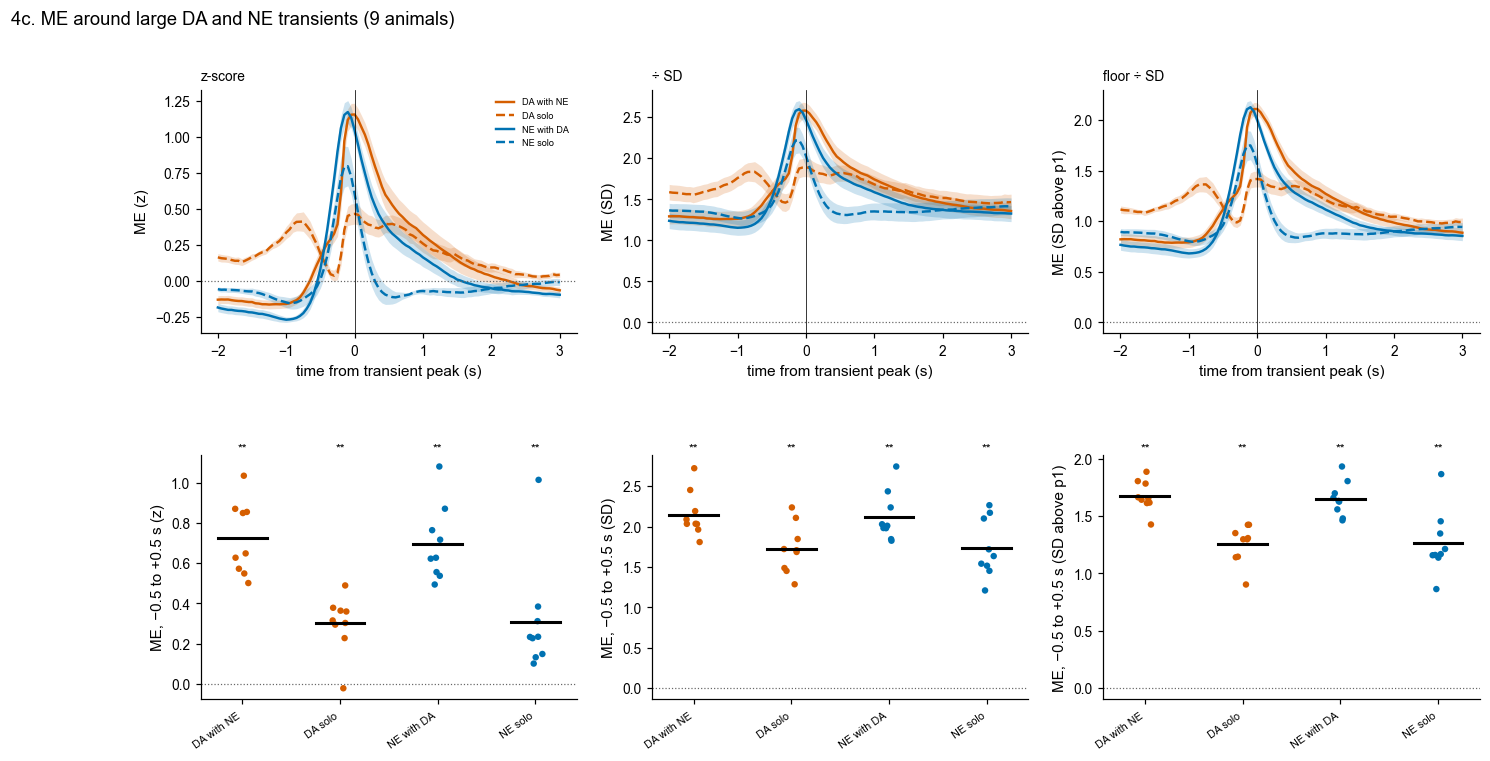

In [10]:
GROUPS = [("da", True), ("da", False), ("ne", True), ("ne", False)]
GROUP_LABEL = {("da", True): "DA with NE", ("da", False): "DA solo",
               ("ne", True): "NE with DA", ("ne", False): "NE solo"}
eta_tr = {(sc, g): [] for sc in SCALES for g in GROUPS}
rows = []
for p in pairs:
    z = p["z"]
    r = dict(subject=p["subject"], session=p["session"])
    for s, o in (("da", "ne"), ("ne", "da")):
        big = fu.large_transients(z[s], z[o], p["t0"], FS, LARGE_PROM, PARTNER_PROM, MATCH_WIN_S, MIN_SEP_S)
        for partner in (True, False):
            t = big.loc[big["partner"] == partner, "t"].to_numpy()
            if len(t) < 3:
                continue
            for sc in SCALES:
                x = p["me"][sc]
                eta_tr[(sc, (s, partner))].append((p["subject"], np.nanmean(su.peri_event_grid(x, p["t0"], FS, t, ETA_LAGS), 0)))
                r[f"{sc}|{GROUP_LABEL[(s, partner)]}"] = np.nanmean(su.window_mean_grid(x, p["t0"], FS, t, *PEAK_WIN))
    rows.append(r)
tr_animal = st.animal_means(pd.DataFrame(rows), [f"{sc}|{GROUP_LABEL[g]}" for sc in SCALES for g in GROUPS],
                            by_session=False)
for sc in SCALES:
    tr_animal[f"{sc}|DA: solo − with NE"] = tr_animal[f"{sc}|DA solo"] - tr_animal[f"{sc}|DA with NE"]
    tr_animal[f"{sc}|NE: solo − with DA"] = tr_animal[f"{sc}|NE solo"] - tr_animal[f"{sc}|NE with DA"]

fig, axes = plt.subplots(2, len(SCALES), figsize=(15, 7.2), gridspec_kw=dict(hspace=0.5))
SIG_COLOR = {"da": OKABE_ITO["vermillion"], "ne": OKABE_ITO["blue"]}
for j, sc in enumerate(SCALES):
    ax = axes[0, j]
    for (s, partner) in GROUPS:
        pu.plot_mean_sem(ax, ETA_LAGS, animal_traces(eta_tr[(sc, (s, partner))]), SIG_COLOR[s],
                         GROUP_LABEL[(s, partner)], ls="-" if partner else "--")
    ax.axvline(0, color="k", lw=0.5)
    ax.axhline(0, color=PALETTE["neutral"], lw=0.8, ls=":")
    ax.set_xlabel("time from transient peak (s)")
    ax.set_ylabel(f"ME ({SCALE_UNIT[sc]})")
    ax.set_title(sc, loc="left", fontsize=9)
    if j == 0:
        ax.legend(fontsize=6)
    style_ax(ax)
    pu.strip_by_measure(axes[1, j], tr_animal, [f"{sc}|{GROUP_LABEL[g]}" for g in GROUPS],
                        [GROUP_LABEL[g] for g in GROUPS], [SIG_COLOR[s] for s, _ in GROUPS],
                        f"ME, −0.5 to +0.5 s ({SCALE_UNIT[sc]})", connect=False, rng=np.random.default_rng(0))
    axes[1, j].tick_params(axis="x", labelrotation=35, labelsize=7)
fig.suptitle(f"4c. ME around large DA and NE transients ({N_ANIMALS} animals)", x=0.01, ha="left")
save_fig(fig, "men_03_4c_transients", fig_dir=FIG_DIR, save=SAVE_FIG)
plt.show()

### 4d. Outcome and RPE terms of ME (`fip_16` §6b)

`fu.fit_rpe_terms` on the trial's ME 0–2 s after the outcome minus 1 s before the go cue.

87 sessions in the RPE fits


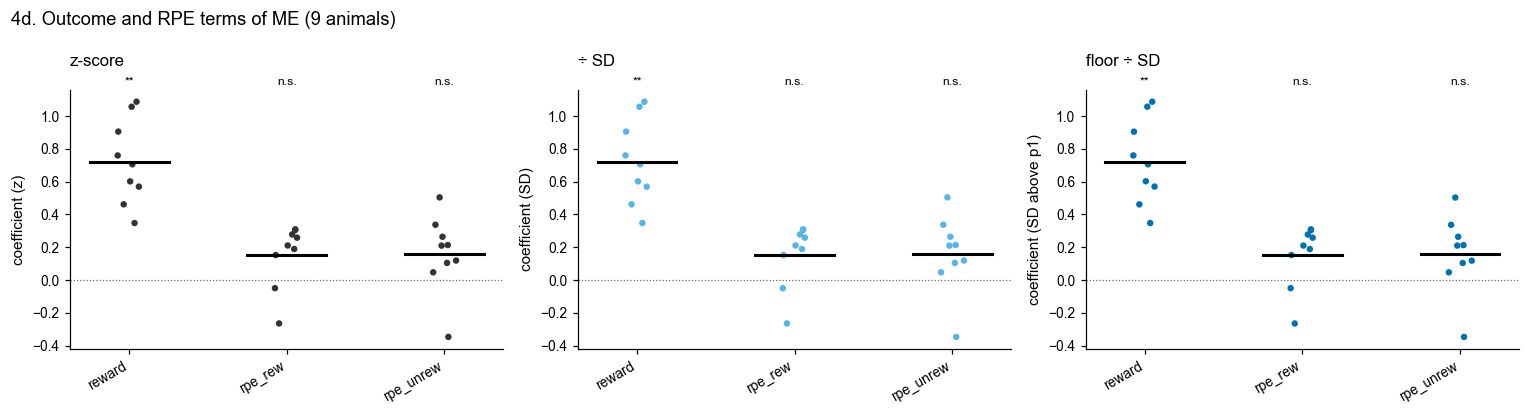

In [11]:
rpe_rows = []
for p in pairs:
    tr = fu.trial_measures(p, {"out": OUTCOME_WIN}, baseline=BASELINE_WIN)
    cue = tr["goCue_start_time_in_session"].to_numpy()
    out = tr["reward_outcome_time_in_session"].to_numpy()
    for sc in SCALES:
        me = p["me"][sc]
        pre = su.window_mean_grid(me, p["t0"], FS, cue, *BASELINE_WIN)
        tr[f"me_out|{sc}"] = su.window_mean_grid(me, p["t0"], FS, out, *OUTCOME_WIN) - pre
    tr = tr[tr["responded"] & ~(tr["extra_reward"].fillna(0) > 0)]
    if tr.groupby("rewarded")["RPE_earned"].std().min() < MIN_RPE_SD:
        continue
    r = dict(subject=p["subject"], session=p["session"])
    for sc in SCALES:
        b = fu.fit_rpe_terms(tr, f"me_out|{sc}", covariates=RPE_NUISANCE)
        r.update({f"{sc}|ME {t}": b[t] for t in TERMS})
        for s in ("da", "ne"):   # section 5: DA/NE terms with ME as a covariate
            b = fu.fit_rpe_terms(tr, f"{s}_out",
                                 covariates=RPE_NUISANCE + [f"me_out|{sc}"])
            r.update({f"{sc}|{s.upper()} {t} with ME": b[t] for t in TERMS})
            r[f"{sc}|{s.upper()} ME coefficient"] = b[f"me_out|{sc}"]
    rpe_rows.append(r)
rpe_sess = pd.DataFrame(rpe_rows)
rpe_animal = st.animal_means(rpe_sess, [c for c in rpe_sess if c not in ("subject", "session")], by_session=False)
print(f"{len(rpe_sess)} sessions in the RPE fits")

fig, axes = plt.subplots(1, len(SCALES), figsize=(14, 3.8))
for ax, sc in zip(axes, SCALES):
    pu.strip_by_measure(ax, rpe_animal, [f"{sc}|ME {t}" for t in TERMS], TERMS, [SCALE_COLOR[sc]] * 3,
                        f"coefficient ({SCALE_UNIT[sc]})", title=sc, connect=False, rng=np.random.default_rng(0))
fig.suptitle(f"4d. Outcome and RPE terms of ME ({N_ANIMALS} animals)", x=0.01, ha="left")
fig.tight_layout()
save_fig(fig, "men_03_4d_me_rpe_terms", fig_dir=FIG_DIR, save=SAVE_FIG)
plt.show()

## 5. Analyses that do not change

Within a session each scale is a + b·ME (for floor ÷ SD, up to the clipping of the lowest 1%). A
correlation, a regression with an intercept, and the coefficients of the *other* regressors are
unchanged by that, so these are the same on every scale, apart from the clipping. Checked numerically:
DA–ME and NE–ME r (`fip_10`) in every session; R² of task + ME (`fip_13`) in the first sessions; DA/NE
terms with ME as a covariate (`fip_16` §6c).

In [12]:
dev = {"r": 0.0, "r2": 0.0, "rpe terms with ME": 0.0}
for p in pairs:
    for s in ("da", "ne"):
        r = [np.corrcoef(p["z"][s], p["me"][sc])[0, 1] for sc in SCALES]
        dev["r"] = max(dev["r"], np.ptp(r))
for p in pairs[:N_R2_SESSIONS]:
    r2 = [[fu.task_residuals(p, KERNEL_S, extra=fu.lagged_columns(p["me"][sc], FS, ME_LAGS_S))[f"{s}_r2"]
           for sc in SCALES] for s in ("da", "ne")]
    dev["r2"] = max(dev["r2"], np.ptp(r2, axis=1).max())
for s in ("DA", "NE"):
    for t in TERMS:
        v = rpe_sess[[f"{sc}|{s} {t} with ME" for sc in SCALES]].to_numpy()
        dev["rpe terms with ME"] = max(dev["rpe terms with ME"], np.nanmax(np.ptp(v, axis=1)))
for k, v in dev.items():
    print(f"largest difference across scales, {k}: {v:.2e}")

largest difference across scales, r: 2.08e-04
largest difference across scales, r2: 1.80e-04
largest difference across scales, rpe terms with ME: 1.42e-03


## 6. Numbers

Mean over animals (in each scale's units), Wilcoxon p across animals against zero, and animals above
zero. The scales differ in units, so compare p and the animal count across columns, not the means.

In [13]:
def row(section, measure, df, cols):
    out = dict(section=section, measure=measure)
    for sc, c in zip(SCALES, cols):
        v = df[c]
        m, pv, n = st.wilcoxon_animals(v)
        out[(sc, "mean")] = round(m, 3)
        out[(sc, "p")] = round(pv, 4)
        out[(sc, "+")] = f"{int((v > 0).sum())}/{n}"
    return out


S = []
for t in TYPES + ["uninstructed − instructed unrewarded", "instructed rewarded − unrewarded"]:
    S.append(row("4b", f"ME response: {t}", type_animal, [f"{sc}|{t}" for sc in SCALES]))
for g in [GROUP_LABEL[g] for g in GROUPS] + ["DA: solo − with NE", "NE: solo − with DA"]:
    S.append(row("4c", f"ME at transient: {g}", tr_animal, [f"{sc}|{g}" for sc in SCALES]))
for t in TERMS:
    S.append(row("4d", f"ME {t}", rpe_animal, [f"{sc}|ME {t}" for sc in SCALES]))
for s in ("DA", "NE"):
    S.append(row("4d", f"{s} ME coefficient", rpe_animal, [f"{sc}|{s} ME coefficient" for sc in SCALES]))
numbers = pd.DataFrame(S).set_index(["section", "measure"])
numbers.columns = pd.MultiIndex.from_tuples(numbers.columns)
numbers

z-score                ÷ SD              floor ÷ SD             
                                                             mean       p    +   mean       p    +       mean       p    +
section measure                                                                                                           
4b      ME response: instructed, rewarded                   1.627  0.0039  9/9  1.627  0.0039  9/9      1.627  0.0039  9/9
        ME response: instructed, unrewarded                 1.014  0.0039  9/9  1.014  0.0039  9/9      1.013  0.0039  9/9
        ME response: uninstructed lick bout                 0.563  0.0039  9/9  0.563  0.0039  9/9      0.562  0.0039  9/9
        ME response: movement, no lick                      0.469  0.0039  9/9  0.469  0.0039  9/9      0.469  0.0039  9/9
        ME response: uninstructed − instructed unrewarded  -0.451  0.0273  2/9 -0.451  0.0273  2/9     -0.451  0.0273  2/9
        ME response: instructed rewarded − unrewarded       0.613  0.0039  9/9  0.613  0.0039  9/9      0.613  0.0039  9/9
4c      ME at transient: DA with NE                         0.723  0.0039  9/9  2.148  0.0039  9/9      1.676  0.0039  9/9
        ME at transient: DA solo                            0.301  0.0078  8/9  1.726  0.0039  9/9      1.255  0.0039  9/9
        ME at transient: NE with DA                         0.697  0.0039  9/9  2.121  0.0039  9/9      1.650  0.0039  9/9
        ME at transient: NE solo                            0.310  0.0039  9/9  1.735  0.0039  9/9      1.263  0.0039  9/9
        ME at transient: DA: solo − with NE                -0.422  0.0039  0/9 -0.422  0.0039  0/9     -0.422  0.0039  0/9
        ME at transient: NE: solo − with DA                -0.387  0.0039  0/9 -0.387  0.0039  0/9     -0.387  0.0039  0/9
4d      ME reward                                           0.721  0.0039  9/9  0.721  0.0039  9/9      0.721  0.0039  9/9
        ME rpe_rew                                          0.154  0.0742  7/9  0.154  0.0742  7/9      0.154  0.0742  7/9
        ME rpe_unrew                                        0.161  0.0977  8/9  0.161  0.0977  8/9      0.161  0.0977  8/9
        DA ME coefficient                                   0.125  0.0391  7/9  0.125  0.0391  7/9      0.125  0.0391  7/9
        NE ME coefficient                                   0.708  0.0039  9/9  0.708  0.0039  9/9      0.708  0.0039  9/9